# CA2, Phase 3: Roaming Between APs and the Sticky Client

This notebook loads the OMNeT++/INET vector results from `results/`, analyzes handover anatomy and outage durations (`Walk` vs. `ScanNeighbor`), transforms `Survey` SNIR traces to received power, evaluates our custom hysteresis + moving-average handover FSM, and exports all 300-DPI figures to `../report/figures/`.

- Group parameters are loaded dynamically from `../params.json`.
- Includes both `omnetpp.scave.results` support (WSL2 OMNeT++ `.venv`) and a pure-Python 4-column `.vec` fallback parser (Windows `.venv`).

In [1]:
from collections import deque
import glob
import json
import os

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

try:
    from omnetpp.scave import results
    HAS_SCAVE = True
except ImportError:
    HAS_SCAVE = False
    print("Note: omnetpp.scave not installed; using built-in pure-Python .vec parser.")

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

D = P["D"]
V = P["v"]
BI = P["BI"] / 1000.0
N_CH = P["nCh"]
ALPHA = P["alpha"]
SIGMA = P["sigma"]
T_WALK = D / V

# Physical constants verified from INET 4.7.0 / Walk-#0.sca
PT_MW = 20.0
PT_DBM = 10.0 * np.log10(PT_MW)  # 13.0103 dBm
NOISE_DBM = -110.0               # IsotropicScalarBackgroundNoise.power
SENS_DBM = -85.0                 # minReceptionPower
AP1_POS = (50.0, 100.0)
AP2_POS = (50.0 + D, 100.0)
WALK_Y = 102.0
C_LIGHT = 299792458.0

FIGURES_DIR = os.path.join("..", "report", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

print(f"students = {', '.join(P['students'])}")
print(f"D = {D} m, v = {V} m/s, BI = {BI * 1000:.0f} ms, nCh = {N_CH}, alpha = {ALPHA}, sigma = {SIGMA} dB, walk = {T_WALK:.2f} s")

Note: omnetpp.scave not installed; using built-in pure-Python .vec parser.
students = 810102460, 810102585
D = 51 m, v = 1.75 m/s, BI = 100 ms, nCh = 6, alpha = 3.2, sigma = 3 dB, walk = 29.14 s


## Loading results

`load_vectors(config)` returns all vectors of one config (`repetition`, `module`, `name`, `vectime`, `vecvalue`).  
`vector(vecs, rep, module, name)` returns `(vectime, vecvalue)` for a given repetition and module.

In [2]:
RESULTS = "results"


def _parse_vec_fallback(pattern):
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No .vec files matched: {pattern}")

    rows = []
    for fp in files:
        rep = None
        vmeta = {}
        vtime = {}
        vval = {}
        with open(fp, "r", encoding="utf-8", errors="ignore") as f:
            for raw in f:
                line = raw.strip()
                if not line:
                    continue
                if line.startswith("attr repetition "):
                    rep = int(line.split()[2])
                elif line.startswith("vector "):
                    parts = line.split()
                    vid = parts[1]
                    vmeta[vid] = (parts[2], parts[3])
                    vtime[vid] = []
                    vval[vid] = []
                elif line[0].isdigit():
                    # OMNeT++ .vec data lines have 4 columns: vector_id, event_nr, sim_time, value
                    parts = line.split()
                    if len(parts) >= 4 and parts[0] in vtime:
                        vtime[parts[0]].append(float(parts[2]))
                        vval[parts[0]].append(float(parts[3]))
        for vid, (mod, name) in vmeta.items():
            if vtime[vid]:
                rows.append({
                    "repetition": rep,
                    "module": mod,
                    "name": name,
                    "vectime": np.array(vtime[vid], dtype=float),
                    "vecvalue": np.array(vval[vid], dtype=float),
                })
    return pd.DataFrame(rows)


def load_vectors(config):
    pattern = os.path.join(RESULTS, f"{config}-*.vec")
    if HAS_SCAVE:
        df = results.read_result_files(pattern)
        vecs = results.get_vectors(df, include_itervars=True, include_runattrs=True)
        vecs["repetition"] = pd.to_numeric(vecs["repetition"])
        return vecs
    return _parse_vec_fallback(pattern)


def vector(vecs, rep, module, name):
    row = vecs[(vecs.repetition == rep) & (vecs.module == "Roaming." + module) & (vecs.name == name)]
    if row.empty:
        return np.array([]), np.array([])
    return row.iloc[0].vectime, row.iloc[0].vecvalue


def ci95(values):
    arr = np.asarray(values, dtype=float)
    mean = float(np.mean(arr))
    if len(arr) < 2:
        return mean, 0.0
    t_crit = float(stats.t.ppf(0.975, df=len(arr) - 1))
    hw = t_crit * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
    return mean, hw

In [3]:
# Starter sanity check: first 5 beacons of ap1 in Survey rep 0
survey = load_vectors("Survey")
t0, snir0 = vector(survey, 0, "meter.wlan[0].radio", "minSnir:vector")
pd.DataFrame({"t (s)": t0[:5], "SNIR": snir0[:5], "Pr (dBm)": NOISE_DBM + 10.0 * np.log10(snir0[:5])})

,t (s),SNIR,Pr (dBm)
0,0.054981,2.966560e+06,-45.277468
1,0.154981,2.984230e+06,-45.251676
2,0.254981,1.286149e+06,-48.907086
3,0.354981,4.502688e+06,-43.465282
4,0.454981,4.267054e+06,-43.698719


## 3-1 Anatomy of a handover (Questions 5-1 to 5-3)

In [4]:
walk = load_vectors("Walk")
scan_nbr = load_vectors("ScanNeighbor")

# Q5-1: Detailed timeline for Walk repetition 0
t_ap1, _ = vector(walk, 0, "ap1.sink", "packets:vector(packetLength)")
t_ap2, _ = vector(walk, 0, "ap2.sink", "packets:vector(packetLength)")
t_sr, v_sr = vector(walk, 0, "host.wlan.agent", "sentRequest:vector")
t_ac, v_ac = vector(walk, 0, "host.wlan.agent", "acceptConfirm:vector")
t_rc, v_rc = vector(walk, 0, "host.wlan.radio", "radioChannel:vector")

# Isolate handover phase (after t > 5s)
events_q51 = [
    ("Last voice frame at ap1.sink", float(t_ap1[-1]), "Associated (ap1)"),
]
for t, c in zip(t_sr, v_sr):
    if t > 5.0:
        lbl = {1: "sentRequest(1: Scan)", 2: "sentRequest(2: Auth)", 4: "sentRequest(4: Assoc)"}[int(c)]
        tr = {1: "Associated -> Scanning", 2: "Scanning -> Authenticating", 4: "Authenticating -> Associating"}[int(c)]
        events_q51.append((lbl, float(t), tr))
for t, c in zip(t_ac, v_ac):
    if t > 5.0:
        lbl = {1: "acceptConfirm(1: Scan OK)", 2: "acceptConfirm(2: Auth OK)", 4: "acceptConfirm(4: Assoc OK)"}[int(c)]
        tr = {1: "Scanning -> Authenticating", 2: "Authenticating -> Associating", 4: "Associating -> Associated (ap2)"}[int(c)]
        events_q51.append((lbl, float(t), tr))
for t, ch in zip(t_rc, v_rc):
    if t > 5.0:
        events_q51.append((f"radioChannel -> {int(ch)}", float(t), "Scanning dwell / target tune"))
events_q51.append(("First voice frame at ap2.sink", float(t_ap2[0]), "Associated (ap2)"))

timeline_df = pd.DataFrame(events_q51, columns=["Event", "Time_s", "FSM_Transition"]).sort_values("Time_s").reset_index(drop=True)
timeline_df["Delta_from_prev_ms"] = timeline_df["Time_s"].diff().fillna(0.0) * 1e3
print("=== Q5-1: Handover Timeline (Walk rep 0) ===")
display(timeline_df)

=== Q5-1: Handover Timeline (Walk rep 0) ===


,Event,Time_s,FSM_Transition,Delta_from_prev_ms
0,Last voice frame at ap1.sink,22.000152,Associated (ap1),0.000000
1,sentRequest(1: Scan),22.009385,Associated -> Scanning,9.232460
2,radioChannel -> 0,22.009385,Scanning dwell / target tune,0.000000
3,radioChannel -> 1,22.259385,Scanning dwell / target tune,250.000000
4,radioChannel -> 2,22.759385,Scanning dwell / target tune,500.000000
5,radioChannel -> 3,22.909385,Scanning dwell / target tune,150.000000
6,radioChannel -> 4,23.309385,Scanning dwell / target tune,400.000000
7,radioChannel -> 5,23.559385,Scanning dwell / target tune,250.000000
8,sentRequest(2: Auth),23.809385,Scanning -> Authenticating,250.000000
9,radioChannel -> 3,23.809385,Scanning dwell / target tune,0.000000


In [5]:
# Q5-2 & Q5-3: Analytical vs Simulation Outage (Walk vs ScanNeighbor)
PROBE_DELAY = 0.100
MIN_CH_TIME = 0.150
MAX_CH_TIME = 0.300


def analytical_scan_time(n_ch, k_active, probe_delay=PROBE_DELAY, min_ch=MIN_CH_TIME, max_ch=MAX_CH_TIME):
    return n_ch * probe_delay + (n_ch - k_active) * min_ch + k_active * max_ch


def summarize_roaming_runs(vecs, label):
    rows = []
    for rep in sorted(vecs["repetition"].unique()):
        t1, _ = vector(vecs, rep, "ap1.sink", "packets:vector(packetLength)")
        t2, _ = vector(vecs, rep, "ap2.sink", "packets:vector(packetLength)")
        tsr, vsr = vector(vecs, rep, "host.wlan.agent", "sentRequest:vector")
        tac, vac = vector(vecs, rep, "host.wlan.agent", "acceptConfirm:vector")
        scans = tsr[vsr == 1]
        confs = tac[vac == 1]
        t_scan_start = float(scans[1] if len(scans) > 1 else scans[0])
        t_scan_end = float(confs[1] if len(confs) > 1 else confs[0])
        outage = float(t2[0] - t1[-1])
        x_ho = min(V * t_scan_start, D)
        rows.append({
            "config": label,
            "repetition": int(rep),
            "t_last_ap1_s": float(t1[-1]),
            "t_scan_start_s": t_scan_start,
            "x_handover_m": x_ho,
            "scan_dur_s": t_scan_end - t_scan_start,
            "t_first_ap2_s": float(t2[0]),
            "outage_s": outage,
        })
    return pd.DataFrame(rows)


walk_df = summarize_roaming_runs(walk, "Walk")
nbr_df = summarize_roaming_runs(scan_nbr, "ScanNeighbor")

t_scan_walk_pred = analytical_scan_time(N_CH, 2)
t_scan_nbr_pred = analytical_scan_time(2, 2)

for name, df, pred in [("Walk", walk_df, t_scan_walk_pred), ("ScanNeighbor", nbr_df, t_scan_nbr_pred)]:
    om, oci = ci95(df["outage_s"])
    sm, sci = ci95(df["scan_dur_s"])
    xm, xci = ci95(df["x_handover_m"])
    print(
        f"=== {name} ===\n"
        f"  Analytical T_scan = {pred:.4f} s\n"
        f"  Measured Scan Dur = {sm:.4f} +/- {sci:.4f} s\n"
        f"  Measured Outage   = {om:.4f} +/- {oci:.4f} s\n"
        f"  Handover Position = {xm:.2f} +/- {xci:.2f} m (delay past midpoint {D/2:.1f} m = {xm - D/2:.2f} m / {(xm - D/2)/V:.2f} s)"
    )
display(pd.concat([walk_df, nbr_df], ignore_index=True))

=== Walk ===
  Analytical T_scan = 1.8000 s
  Measured Scan Dur = 1.7700 +/- 0.1558 s
  Measured Outage   = 1.7919 +/- 0.1605 s
  Handover Position = 39.45 +/- 3.25 m (delay past midpoint 25.5 m = 13.95 m / 7.97 s)
=== ScanNeighbor ===
  Analytical T_scan = 0.8000 s
  Measured Scan Dur = 0.8000 +/- 0.0000 s
  Measured Outage   = 0.8197 +/- 0.0006 s
  Handover Position = 39.87 +/- 1.46 m (delay past midpoint 25.5 m = 14.37 m / 8.21 s)


,config,repetition,t_last_ap1_s,t_scan_start_s,x_handover_m,scan_dur_s,t_first_ap2_s,outage_s
0,Walk,0,22.000152,22.009385,38.516423,1.80,23.820152,1.820000
1,Walk,1,22.640152,22.649819,39.637183,1.80,24.460152,1.820000
2,Walk,2,23.460152,23.468608,41.070065,1.65,25.120228,1.660075
3,Walk,3,24.240476,24.257173,42.450052,1.65,25.920152,1.679676
4,Walk,4,20.320521,20.340162,35.595284,1.95,22.300152,1.979631
5,ScanNeighbor,0,23.000998,23.009385,40.266423,0.80,23.820152,0.819154
6,ScanNeighbor,1,23.040152,23.049819,40.337183,0.80,23.860152,0.820000
7,ScanNeighbor,2,22.060989,22.068608,38.620065,0.80,22.880152,0.819163
8,ScanNeighbor,3,23.640152,23.657173,41.400052,0.80,24.460152,0.820000
9,ScanNeighbor,4,22.140152,22.140162,38.745284,0.80,22.960152,0.820000


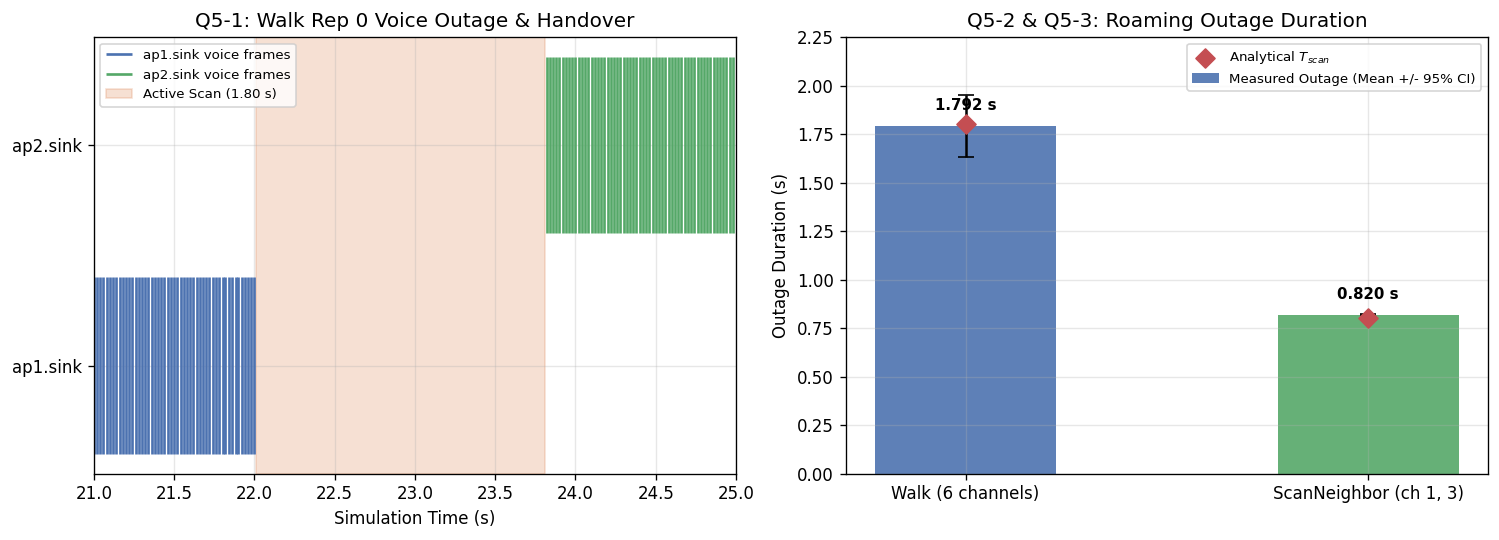

In [6]:
# Figure 1: Handover Timeline (Walk rep 0) & Outage Comparison (Walk vs ScanNeighbor)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.6))

t_w0_ap1, _ = vector(walk, 0, "ap1.sink", "packets:vector(packetLength)")
t_w0_ap2, _ = vector(walk, 0, "ap2.sink", "packets:vector(packetLength)")
w_win1 = t_w0_ap1[(t_w0_ap1 >= 21.0) & (t_w0_ap1 <= 25.0)]
w_win2 = t_w0_ap2[(t_w0_ap2 >= 21.0) & (t_w0_ap2 <= 25.0)]

ax1.vlines(w_win1, 0.1, 0.9, color="#4C72B0", lw=1.6, label="ap1.sink voice frames")
ax1.vlines(w_win2, 1.1, 1.9, color="#55A868", lw=1.6, label="ap2.sink voice frames")
t_s0 = walk_df.loc[0, "t_scan_start_s"]
t_e0 = t_s0 + walk_df.loc[0, "scan_dur_s"]
ax1.axvspan(t_s0, t_e0, color="#DD8452", alpha=0.25, label=f"Active Scan ({walk_df.loc[0, 'scan_dur_s']:.2f} s)")
ax1.set_yticks([0.5, 1.5])
ax1.set_yticklabels(["ap1.sink", "ap2.sink"])
ax1.set_xlim(21.0, 25.0)
ax1.set_xlabel("Simulation Time (s)")
ax1.set_title("Q5-1: Walk Rep 0 Voice Outage & Handover")
ax1.legend(loc="upper left", fontsize=8)

labels = ["Walk (6 channels)", "ScanNeighbor (ch 1, 3)"]
means = [ci95(walk_df["outage_s"])[0], ci95(nbr_df["outage_s"])[0]]
cis = [ci95(walk_df["outage_s"])[1], ci95(nbr_df["outage_s"])[1]]
preds = [t_scan_walk_pred, t_scan_nbr_pred]
bx = np.arange(2)
ax2.bar(bx, means, 0.45, yerr=cis, capsize=5, color=["#4C72B0", "#55A868"], alpha=0.9, label="Measured Outage (Mean +/- 95% CI)")
ax2.scatter(bx, preds, marker="D", s=65, color="#C44E52", zorder=5, label="Analytical $T_{scan}$")
for idx, (m, p) in enumerate(zip(means, preds)):
    ax2.text(idx, m + 0.08, f"{m:.3f} s", ha="center", fontweight="bold", fontsize=9)
ax2.set_xticks(bx)
ax2.set_xticklabels(labels)
ax2.set_ylabel("Outage Duration (s)")
ax2.set_ylim(0, 2.25)
ax2.set_title("Q5-2 & Q5-3: Roaming Outage Duration")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase3_handover_outage.png"), dpi=300, bbox_inches="tight")
plt.show()

## 3-2 The sticky client (Questions 5-4 and 5-5)

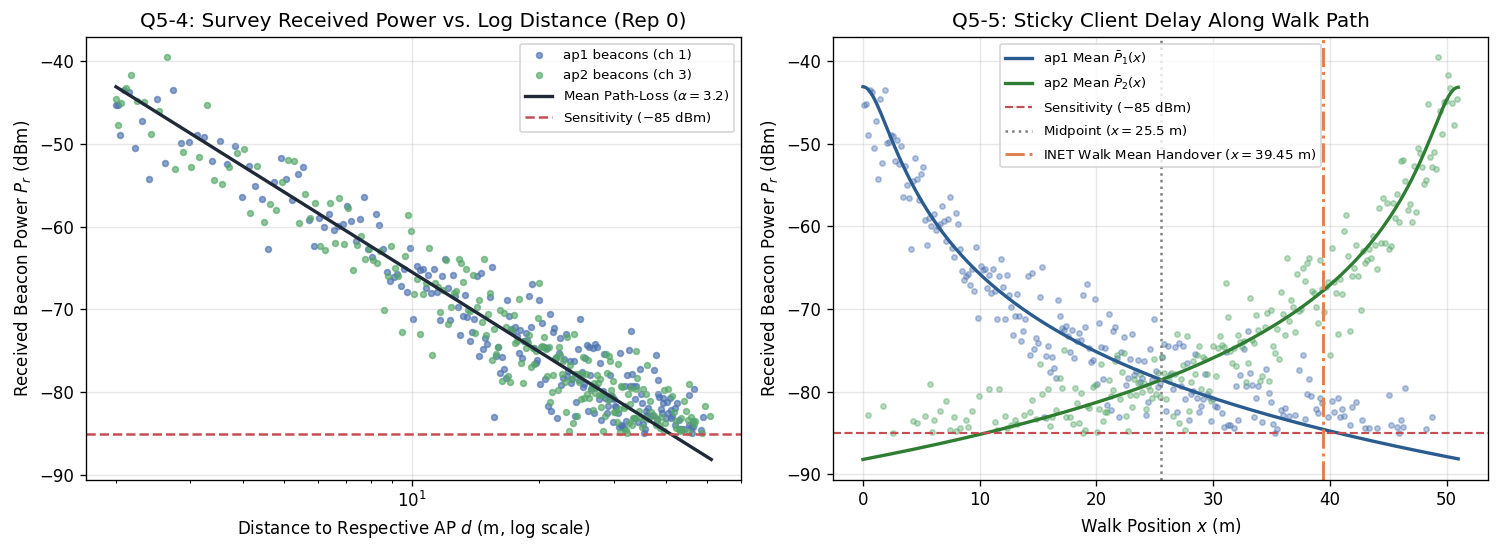

PL(d0=1m): ch1=46.48 dB, ch3=46.55 dB, Pt=13.01 dBm
Midpoint x = 25.50 m (d = 25.58 m, P_mean ~ -78.52 dBm)
Sticky client delay in Walk: 13.95 m = 7.97 s past midpoint


In [7]:
# Q5-4 & Q5-5: Convert Survey SNIR to dBm, plot vs log-distance, and quantify sticky delay
t_s0_1, snir_s0_1 = vector(survey, 0, "meter.wlan[0].radio", "minSnir:vector")
t_s0_2, snir_s0_2 = vector(survey, 0, "meter.wlan[1].radio", "minSnir:vector")

m1 = t_s0_1 <= T_WALK
m2 = t_s0_2 <= T_WALK
t1_w, p1_w = t_s0_1[m1], NOISE_DBM + 10.0 * np.log10(snir_s0_1[m1])
t2_w, p2_w = t_s0_2[m2], NOISE_DBM + 10.0 * np.log10(snir_s0_2[m2])

x1_w = V * t1_w
x2_w = V * t2_w
d1_w = np.sqrt(x1_w ** 2 + 2.0 ** 2)
d2_w = np.sqrt((D - x2_w) ** 2 + 2.0 ** 2)

# Free-space PL(d0=1m) at 5030 MHz (ch 1) and 5070 MHz (ch 3)
def pl_d0_db(freq_hz):
    lam = C_LIGHT / freq_hz
    return 20.0 * np.log10(4.0 * np.pi * 1.0 / lam)

pl0_ch1 = pl_d0_db(5030e6)
pl0_ch3 = pl_d0_db(5070e6)
d_grid = np.linspace(2.0, np.sqrt(D ** 2 + 4.0), 300)
p_mean_ch1 = PT_DBM - pl0_ch1 - 10.0 * ALPHA * np.log10(d_grid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.7))

ax1.scatter(d1_w, p1_w, s=12, alpha=0.65, color="#4C72B0", label="ap1 beacons (ch 1)")
ax1.scatter(d2_w, p2_w, s=12, alpha=0.65, color="#55A868", label="ap2 beacons (ch 3)")
ax1.plot(d_grid, p_mean_ch1, color="#1F2937", lw=2.0, label=f"Mean Path-Loss ($\\alpha={ALPHA}$)")
ax1.axhline(SENS_DBM, color="#C44E52", ls="--", lw=1.5, label="Sensitivity ($-85$ dBm)")
ax1.set_xscale("log")
ax1.set_xlabel("Distance to Respective AP $d$ (m, log scale)")
ax1.set_ylabel("Received Beacon Power $P_r$ (dBm)")
ax1.set_title("Q5-4: Survey Received Power vs. Log Distance (Rep 0)")
ax1.legend(fontsize=8)

# Right panel: Spatial power trajectory along x in [0, D] showing sticky client gap
x_grid = np.linspace(0.0, D, 300)
d1_g = np.sqrt(x_grid ** 2 + 2.0 ** 2)
d2_g = np.sqrt((D - x_grid) ** 2 + 2.0 ** 2)
p1_mean_x = PT_DBM - pl0_ch1 - 10.0 * ALPHA * np.log10(d1_g)
p2_mean_x = PT_DBM - pl0_ch3 - 10.0 * ALPHA * np.log10(d2_g)

ax2.scatter(x1_w, p1_w, s=10, alpha=0.4, color="#4C72B0")
ax2.scatter(x2_w, p2_w, s=10, alpha=0.4, color="#55A868")
ax2.plot(x_grid, p1_mean_x, color="#2B5C8F", lw=2.0, label="ap1 Mean $\\bar{P}_1(x)$")
ax2.plot(x_grid, p2_mean_x, color="#2E7D32", lw=2.0, label="ap2 Mean $\\bar{P}_2(x)$")
ax2.axhline(SENS_DBM, color="#C44E52", ls="--", lw=1.3, label="Sensitivity ($-85$ dBm)")
ax2.axvline(D / 2.0, color="gray", ls=":", lw=1.5, label=f"Midpoint ($x={D/2:.1f}$ m)")
ho_mean_x = walk_df["x_handover_m"].mean()
ax2.axvline(ho_mean_x, color="#DD8452", ls="-.", lw=1.8, label=f"INET Walk Mean Handover ($x={ho_mean_x:.2f}$ m)")
ax2.set_xlabel("Walk Position $x$ (m)")
ax2.set_ylabel("Received Beacon Power $P_r$ (dBm)")
ax2.set_title("Q5-5: Sticky Client Delay Along Walk Path")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase3_survey_power_vs_distance.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"PL(d0=1m): ch1={pl0_ch1:.2f} dB, ch3={pl0_ch3:.2f} dB, Pt={PT_DBM:.2f} dBm")
print(f"Midpoint x = {D/2:.2f} m (d = {np.sqrt((D/2)**2 + 4):.2f} m, P_mean ~ {PT_DBM - pl0_ch1 - 10*ALPHA*np.log10(np.sqrt((D/2)**2 + 4)):.2f} dBm)")
print(f"Sticky client delay in Walk: {ho_mean_x - D/2:.2f} m = {(ho_mean_x - D/2)/V:.2f} s past midpoint")

## 3-3 Your roaming algorithm (Questions 5-6 and 5-7)

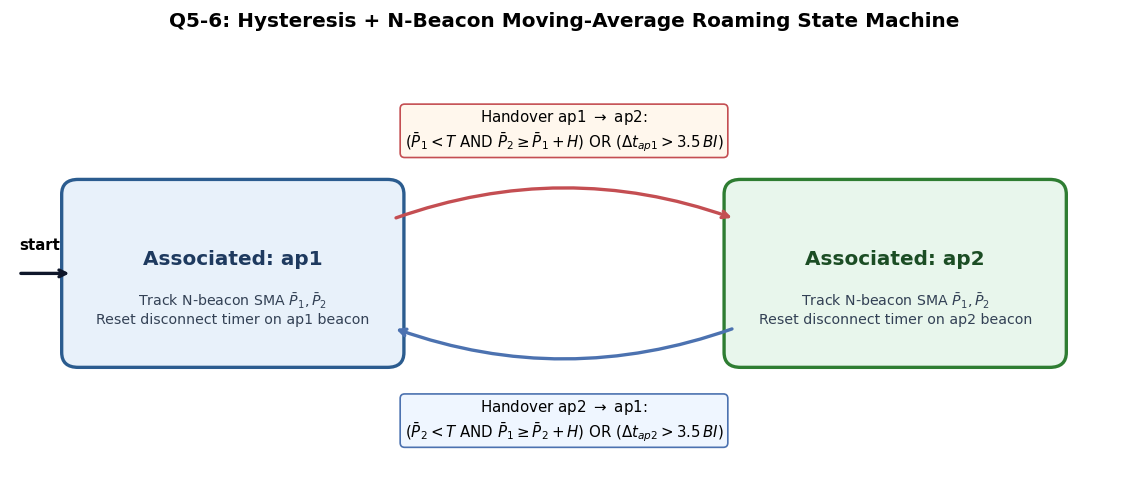

Q5-6(b) Noiseless analytical handover position (H = 6.0 dB): x = 30.92 m


In [8]:
# Q5-6: Render clean FSM state-machine diagram for our proposed handover algorithm
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.6)
ax.axis("off")

box1 = mpatches.FancyBboxPatch((0.6, 1.4), 2.8, 1.6, boxstyle="round,pad=0.15", fc="#E8F1FA", ec="#2B5C8F", lw=2)
box2 = mpatches.FancyBboxPatch((6.6, 1.4), 2.8, 1.6, boxstyle="round,pad=0.15", fc="#E8F6EC", ec="#2E7D32", lw=2)
ax.add_patch(box1)
ax.add_patch(box2)

ax.text(2.0, 2.35, "Associated: ap1", ha="center", va="center", fontsize=12, fontweight="bold", color="#1E3A5F")
ax.text(2.0, 1.85, "Track N-beacon SMA $\\bar{P}_1, \\bar{P}_2$\nReset disconnect timer on ap1 beacon", ha="center", va="center", fontsize=8.5, color="#334155")

ax.text(8.0, 2.35, "Associated: ap2", ha="center", va="center", fontsize=12, fontweight="bold", color="#1B4D24")
ax.text(8.0, 1.85, "Track N-beacon SMA $\\bar{P}_1, \\bar{P}_2$\nReset disconnect timer on ap2 beacon", ha="center", va="center", fontsize=8.5, color="#334155")

# Initial arrow
ax.annotate("", xy=(0.55, 2.2), xytext=(0.05, 2.2), arrowprops=dict(arrowstyle="->", lw=2, color="#0F172A"))
ax.text(0.25, 2.45, "start", ha="center", fontsize=9, fontweight="bold")

# Top arrow: ap1 -> ap2
ax.annotate("", xy=(6.55, 2.75), xytext=(3.45, 2.75),
            arrowprops=dict(arrowstyle="->", lw=2, color="#C44E52", connectionstyle="arc3,rad=-0.18"))
ax.text(5.0, 3.65, "Handover ap1 $\\rightarrow$ ap2:\n($\\bar{P}_1 < T$ AND $\\bar{P}_2 \\geq \\bar{P}_1 + H$) OR ($\\Delta t_{ap1} > 3.5\\,BI$)",
        ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="#FFF7ED", ec="#C44E52"))

# Bottom arrow: ap2 -> ap1
ax.annotate("", xy=(3.45, 1.65), xytext=(6.55, 1.65),
            arrowprops=dict(arrowstyle="->", lw=2, color="#4C72B0", connectionstyle="arc3,rad=-0.18"))
ax.text(5.0, 0.72, "Handover ap2 $\\rightarrow$ ap1:\n($\\bar{P}_2 < T$ AND $\\bar{P}_1 \\geq \\bar{P}_2 + H$) OR ($\\Delta t_{ap2} > 3.5\\,BI$)",
        ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="#EFF6FF", ec="#4C72B0"))

ax.set_title("Q5-6: Hysteresis + N-Beacon Moving-Average Roaming State Machine", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase3_fsm_diagram.png"), dpi=300, bbox_inches="tight")
plt.show()

# Q5-6(b) analytical noiseless handover position for H = 6 dB
H_Q56 = 6.0
x_q56_pred = D / (1.0 + 10.0 ** (-H_Q56 / (10.0 * ALPHA)))
print(f"Q5-6(b) Noiseless analytical handover position (H = {H_Q56} dB): x = {x_q56_pred:.2f} m")

=== Q5-7: FSM Evaluation (T = -75.0 dBm) ===


,N,H_dB,counts,mean_handovers,final_x_mean_m,final_xs,reasons
0,1,0,"[41, 45, 27]",37.666667,32.806949,"[33.17, 34.37, 30.88]","[hyst, hyst, hyst]"
1,1,2,"[23, 23, 13]",19.666667,31.919880,"[33.18, 33.85, 28.73]","[hyst, hyst, hyst]"
2,1,4,"[11, 9, 7]",9.000000,29.853723,"[33.18, 27.65, 28.73]","[hyst, hyst, hyst]"
3,1,6,"[7, 3, 5]",5.000000,29.853723,"[33.18, 27.65, 28.73]","[hyst, hyst, hyst]"
4,1,8,"[3, 1, 3]",2.333333,27.775645,"[27.92, 26.67, 28.73]","[hyst, hyst, hyst]"
5,1,10,"[1, 1, 1]",1.000000,28.101155,"[27.92, 28.17, 28.21]","[hyst, hyst, timeout]"
6,5,0,"[7, 7, 7]",7.000000,27.381949,"[28.27, 27.72, 26.15]","[hyst, hyst, hyst]"
7,5,2,"[1, 1, 1]",1.000000,27.717312,"[28.62, 28.25, 26.28]","[hyst, hyst, hyst]"
8,5,4,"[1, 1, 1]",1.000000,28.742822,"[29.32, 28.87, 28.03]","[hyst, hyst, hyst]"
9,5,6,"[1, 1, 1]",1.000000,29.761547,"[30.73, 30.35, 28.21]","[hyst, hyst, timeout]"


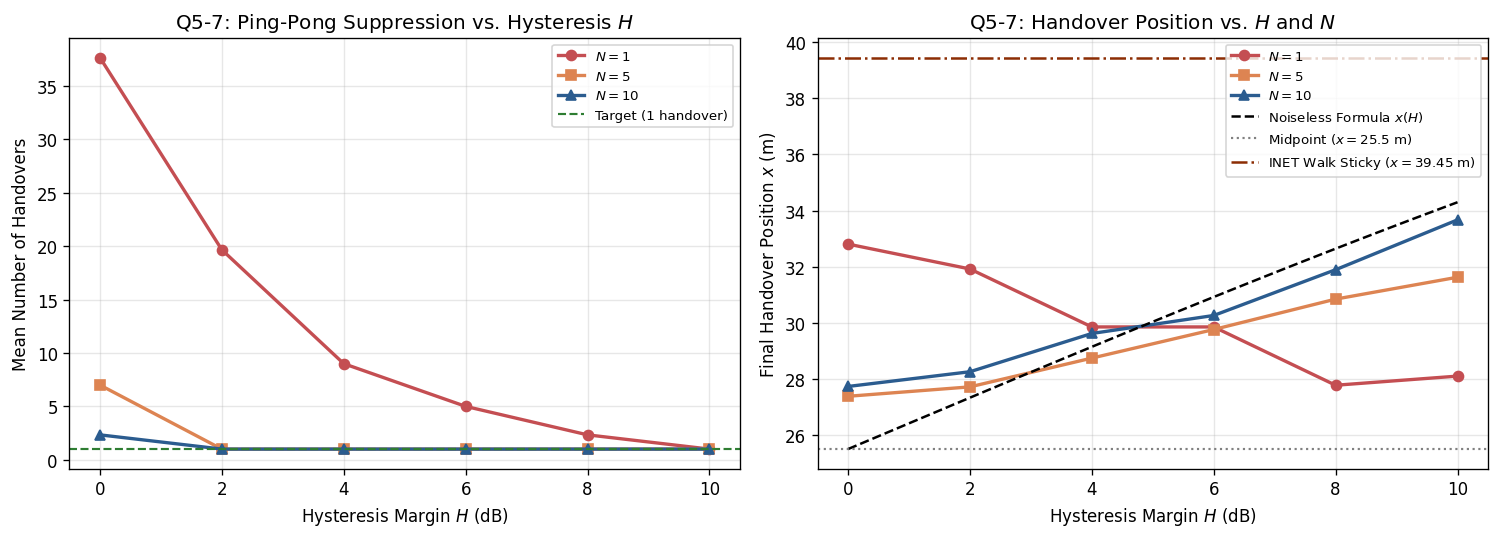

In [9]:
# Q5-7: Chronologically merge Survey beacon streams and evaluate FSM across H and N
def merged_survey_beacons(rep):
    t1, s1 = vector(survey, rep, "meter.wlan[0].radio", "minSnir:vector")
    t2, s2 = vector(survey, rep, "meter.wlan[1].radio", "minSnir:vector")
    p1 = NOISE_DBM + 10.0 * np.log10(s1)
    p2 = NOISE_DBM + 10.0 * np.log10(s2)
    ev1 = list(zip(t1, [1] * len(t1), p1))
    ev2 = list(zip(t2, [2] * len(t2), p2))
    return sorted(ev1 + ev2, key=lambda item: item[0])


def simulate_fsm(events, t_thresh, h_db, n_win, bi=BI):
    hist = {1: deque(maxlen=n_win), 2: deque(maxlen=n_win)}
    last_t = {1: None, 2: None}
    cur_ap = 1
    handovers = []
    for t, ap, p_dbm in events:
        if last_t[cur_ap] is not None and (t - last_t[cur_ap]) > 3.5 * bi:
            other = 2 if cur_ap == 1 else 1
            if hist[other]:
                cur_ap = other
                handovers.append((float(t), float(min(V * t, D)), "timeout", cur_ap))
        hist[ap].append(p_dbm)
        last_t[ap] = t
        other = 2 if cur_ap == 1 else 1
        if hist[cur_ap] and hist[other]:
            est_cur = float(np.mean(hist[cur_ap]))
            est_oth = float(np.mean(hist[other]))
            if est_cur < t_thresh and est_oth >= est_cur + h_db:
                cur_ap = other
                handovers.append((float(t), float(min(V * t, D)), "hyst", cur_ap))
    return handovers


T_THRESH = -75.0  # dBm: 10 dB above sensitivity (-85 dBm), 3.5 dB above midpoint mean (-78.5 dBm)
H_VALUES = [0, 2, 4, 6, 8, 10]
N_VALUES = [1, 5, 10]
REPS = sorted(survey["repetition"].unique())

sweep_rows = []
for n_win in N_VALUES:
    for h_db in H_VALUES:
        counts, final_xs, reasons = [], [], []
        for rep in REPS:
            ev = merged_survey_beacons(rep)
            ho = simulate_fsm(ev, T_THRESH, h_db, n_win)
            counts.append(len(ho))
            final_xs.append(ho[-1][1] if ho else np.nan)
            reasons.append(ho[-1][2] if ho else "none")
        sweep_rows.append({
            "N": n_win,
            "H_dB": h_db,
            "counts": str(counts),
            "mean_handovers": float(np.mean(counts)),
            "final_x_mean_m": float(np.mean(final_xs)),
            "final_xs": [round(x, 2) for x in final_xs],
            "reasons": reasons,
        })

fsm_df = pd.DataFrame(sweep_rows)
print(f"=== Q5-7: FSM Evaluation (T = {T_THRESH} dBm) ===")
display(fsm_df[["N", "H_dB", "counts", "mean_handovers", "final_x_mean_m", "final_xs", "reasons"]])

# Plot Q5-7: Handover Count vs H and Final Handover Position vs H
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.6))
colors = {1: "#C44E52", 5: "#DD8452", 10: "#2B5C8F"}
markers = {1: "o", 5: "s", 10: "^"}

for n_win in N_VALUES:
    sub = fsm_df[fsm_df["N"] == n_win]
    ax1.plot(sub["H_dB"], sub["mean_handovers"], marker=markers[n_win], lw=2, color=colors[n_win], label=f"$N = {n_win}$")
    ax2.plot(sub["H_dB"], sub["final_x_mean_m"], marker=markers[n_win], lw=2, color=colors[n_win], label=f"$N = {n_win}$")

ax1.axhline(1.0, color="#2E7D32", ls="--", lw=1.3, label="Target (1 handover)")
ax1.set_xlabel("Hysteresis Margin $H$ (dB)")
ax1.set_ylabel("Mean Number of Handovers")
ax1.set_title("Q5-7: Ping-Pong Suppression vs. Hysteresis $H$")
ax1.set_xticks(H_VALUES)
ax1.legend(fontsize=8)

h_fine = np.linspace(0, 10, 100)
x_analyt = D / (1.0 + 10.0 ** (-h_fine / (10.0 * ALPHA)))
ax2.plot(h_fine, x_analyt, color="black", ls="--", lw=1.5, label="Noiseless Formula $x(H)$")
ax2.axhline(D / 2.0, color="gray", ls=":", lw=1.3, label=f"Midpoint ($x={D/2:.1f}$ m)")
ax2.axhline(walk_df["x_handover_m"].mean(), color="#8C2D04", ls="-.", lw=1.5, label=f"INET Walk Sticky ($x={walk_df['x_handover_m'].mean():.2f}$ m)")
ax2.set_xlabel("Hysteresis Margin $H$ (dB)")
ax2.set_ylabel("Final Handover Position $x$ (m)")
ax2.set_title("Q5-7: Handover Position vs. $H$ and $N$")
ax2.set_xticks(H_VALUES)
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase3_fsm_sweep.png"), dpi=300, bbox_inches="tight")
plt.show()